## Lab: Market Return Dynamics

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('./data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

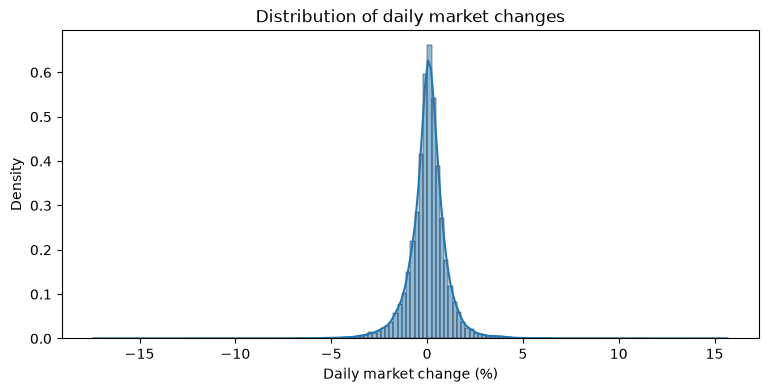

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

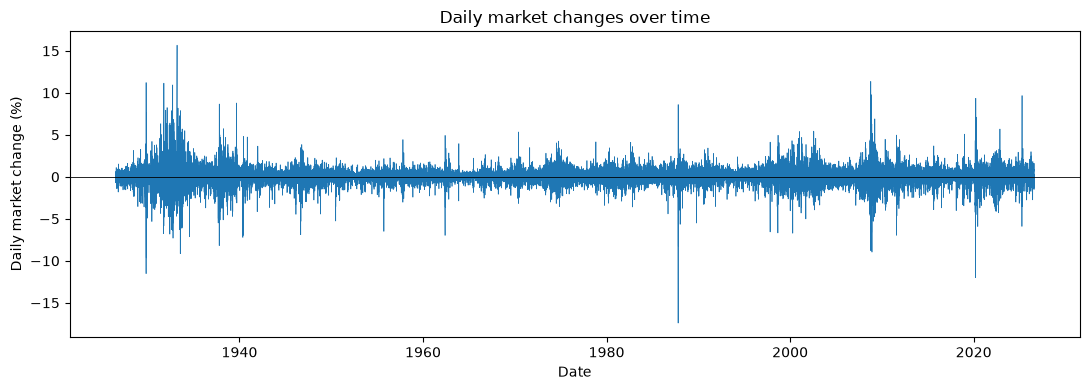

In [4]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

### 1. Part One: Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [5]:
direction_categories = ['Down/ flat', 'Up']
df['direction_t'] = pd.Categorical(
    np.where(df['market_return_pct'] > 0, 'Up', 'Down/ flat'),
    categories=direction_categories
)

In [6]:
# make a categorical column "direction_t" 
df['direction_t'] = pd.Categorical(
    np.where(df['market_return_pct'] > 0, 'Up', 'Down/ flat'),
    categories=direction_categories
)

In [7]:
# make a categorical column "direction_tp1" for the next trading day
df['direction_tp1'] = df['direction_t'].shift(-1)
df['direction_tp1'] = pd.Categorical(
    df['direction_tp1'],
    categories=direction_categories
)

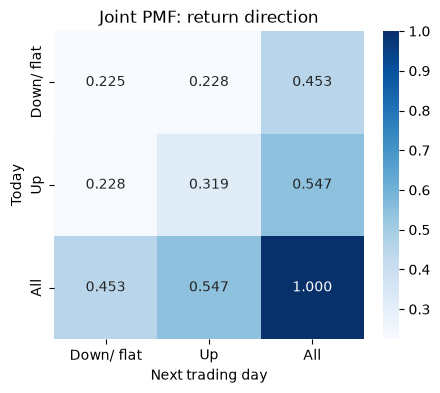

In [8]:
# Plot the joint PMF
fig, ax = plt.subplots(figsize=(5, 4))
joint_pmf = pd.crosstab(
    df['direction_t'], df['direction_tp1'], normalize='all', margins=True
)
sns.heatmap(joint_pmf,
            annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today', title='Joint PMF: return direction')
plt.show()

In [9]:
pd.crosstab(df['direction_t'], df['direction_tp1'], normalize = 'index')

direction_tp1,Down/ flat,Up
direction_t,,
Down/ flat,0.496221,0.503779
Up,0.416974,0.583026


In [10]:
# Plot the conditional PMF

<div class='alert alert-info'><b>Answer the following:</b>

- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

</div>

#### Up transitions are more common because there are more ups in general. You are more likely for Down to Up than Up to Down

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- Subtract the marginal PMF of tomorrow's state from each row of the conditional PMF, and plot the result as a heatmap. If tomorrow's state were independent of today's, every row of the conditional PMF would equal this marginal. Which transitions are more likely than independence predicts, and which are less likely? Does knowing today's state change the forecast for tomorrow?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [11]:
return_categories = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
df['return_bin'] = pd.cut(df['market_return_pct'], bins = [-np.inf, -1, -0.1, 0.1, 1, np.inf], labels = return_categories)

In [12]:
# Count observations in each return bin
bin_counts = df['return_bin'].value_counts(sort=False)
print('Trading days in each bin:')
print(bin_counts)
print(f'\nMost common: {bin_counts.idxmax()} ({bin_counts.max():,} days)')
print(f'Least common: {bin_counts.idxmin()} ({bin_counts.min():,} days)')

# Pair each current return bin with the next trading day's bin
df['y_t'] = df['return_bin']
df['y_tp1'] = df['return_bin'].shift(-1)

Trading days in each bin:
return_bin
Large loss    2759
Small loss    7452
Near zero     3441
Small gain    9785
Large gain    2859
Name: count, dtype: int64

Most common: Small gain (9,785 days)
Least common: Large loss (2,759 days)


In [13]:
df['y_t'] = df['return_bin']
df['y_tp1'] = df['return_bin'].shift(-1)

In [14]:
pd.crosstab(df['y_t'], df['y_tp1'], normalize = True, margins = True)

y_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
y_t,,,,,,
Large loss,0.021335,0.027191,0.009051,0.027800,0.019547,0.104925
Small loss,0.035444,0.088648,0.034151,0.097775,0.027382,0.283400
Near zero,0.009317,0.041985,0.020955,0.049325,0.009279,0.130861
Small gain,0.024986,0.100057,0.055029,0.159422,0.032592,0.372086
Large gain,0.013843,0.025518,0.011637,0.037802,0.019928,0.108728
All,0.104925,0.283400,0.130823,0.372124,0.108728,1.000000


<div class='alert alert-info'><b>Answer the following:</b>

- How many days fall into each of the five bins?  (use value_counts)
- Which are the most or least common?
  
  </div>

#### Large Loss = 2759 days, Small loss = 7452 days, near zero = 3441, small gain = 9785 days, large gain = 2859 days

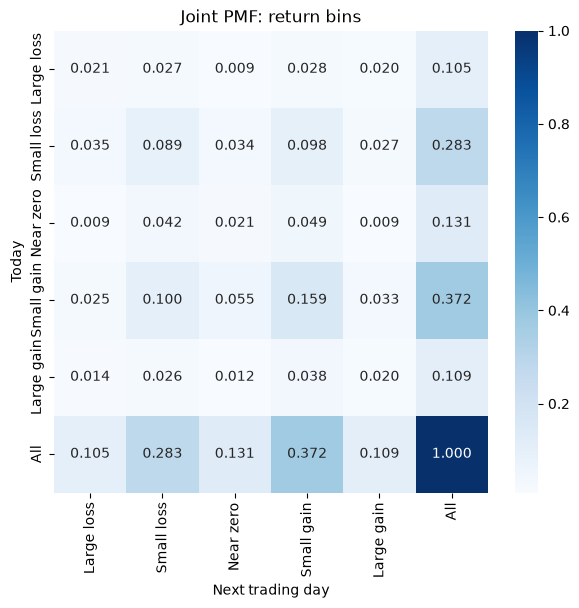

In [15]:
#joint PMF with marginals
joint_pmf = pd.crosstab(
    df['y_t'], df['y_tp1'], normalize=True, margins=True
)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(joint_pmf, annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today',
       title='Joint PMF: return bins')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Which transitions are most likely to occur? 

</div>

#### Small gain transition to small gain is most likely to happen, then small loss to small gain, then small loss to small loss.

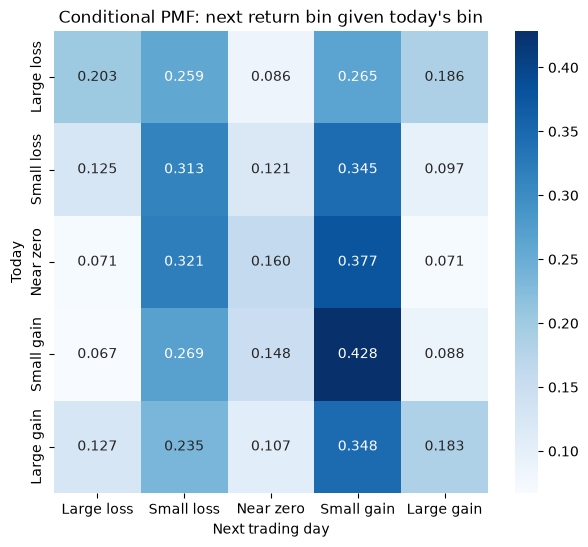

In [16]:
# Conditional PMF: P(y_tp1 | y_t)
conditional_pmf = pd.crosstab(
    df['y_t'], df['y_tp1'], normalize='index'
)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(conditional_pmf, annot=True, fmt='.3f', cmap='Blues', ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today',
       title='Conditional PMF: next return bin given today\'s bin')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- For each current state, which two future states are the most likely? 
- Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? 
- Is it relatively easy or difficult to predict the next state?
</div>

#### Large loss = small gain, small loss | Small loss -> Small gain, small loss | Near zero -> Small gain, small loss | Small gain -> small gain, small loss | Large gain -> Small gain Small loss

#### Each of the rows are not very close to the uniform as small gain and small loss is much more likely after a small gain. 

#### It would be difficult since today's state would shift the probabilities since they are not independent 

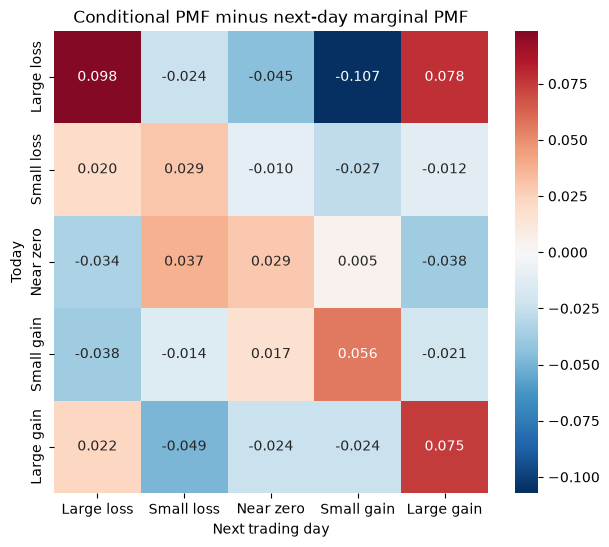

In [17]:
# marginal PMF of tomorrow's state: sum the joint PMF (without margins) down each column
next_state_pmf = joint_pmf.drop(index='All', columns='All').sum(axis='index')

# subtract it from each row of the conditional PMF and plot as a heatmap
conditional_minus_marginal = conditional_pmf.sub(next_state_pmf, axis='columns')

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(conditional_minus_marginal, annot=True, fmt='.3f',
            cmap='RdBu_r', center=0, ax=ax)
ax.set(xlabel='Next trading day', ylabel='Today',
       title='Conditional PMF minus next-day marginal PMF')
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

- Which transitions are more likely than independence predicts, and which are less likely?
- Does knowing today's state change the forecast for tomorrow?
- How is this comparison different from comparing each row to a uniform PMF with probability .2?
</div>

#### The stransition from small gain and small loss are more likely than independence predicts after a large loss or large gain. both small loss and small gain outcomes are also less likely. 

#### Knowing today's state does chagne the forecost from tomorrow, but not by a lot. The next day is still most likely to be a small gain or loss regardless of what today's bin is. 

#### This differs becuase the uniform comparison would treat all five of the fturue states as equally likely. The independence comparison uses tomorro's actual marginal distribution as the baseline, which isn't uniform as small gain and small loss are a lot more common than the other states. 

In [18]:
df['market_return_pct_tp1'] = df['market_return_pct'].shift(-1)

# Conditional distribution of tomorrow's return given today's bin
conditional_return_summary = (
    df.groupby('y_t', observed=True)['market_return_pct_tp1'].describe()
)
conditional_return_summary

,count,mean,std,min,25%,50%,75%,max
y_t,,,,,,,,
Large loss,2759.0,-0.038311,1.720570,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.043814,1.009529,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015013,0.826054,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.106810,0.832186,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163092,1.384086,-12.00,-0.37,0.15,0.73,15.67


<div class='alert alert-info'><b>Answer the following:</b>

- Given the current state, what are the expected percent returns for tomorrow? 
- How do the min and max values for tomorrow vary across states? 
- Which states have the highest standard deviation for tomorrow's percent returns? 
- Describe any patterns in the volatility you notice.
</div>


In [27]:
# Summary of tomorrow's percent return for each of today's five return bins
summary_columns = ['mean', 'min', 'max', 'std']
conditional_return_summary[summary_columns].round(3)

,mean,min,max,std
y_t,,,,
Large loss,-0.038,-17.41,11.22,1.721
Small loss,-0.044,-11.23,11.36,1.010
Near zero,0.015,-8.19,5.49,0.826
Small gain,0.107,-8.25,8.67,0.832
Large gain,0.163,-12.00,15.67,1.384


#### Large loss: -0.04%, Small loss: -0.04%, Near zero: 0.02%, small gain: 0.11%, Large gain: 0.16%

#### The min and maxare the widest after extremem current states. Large loss: −17.41% to 11.22%, Small loss: −11.23% to 11.36%, Near zero: −8.19% to 5.49%, Small gain: −8.25% to 8.67%, Large gain: −12.00% to 15.67%

#### Large loss has the highest std with 1.721 followed by Large Jain with 1.384

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [ ]:
#cut into 21 equal-sized bins and make y_t and y_tp1 columns for the return bins
bins = 21
labels = [f"Q{i+1}" for i in range(bins)]

df['y_t'] = pd.qcut(df['market_return_pct'], q=bins, labels=labels)
df['y_tp1'] = df['y_t'].shift(-1)

df['y_t'].value_counts(sort=False).rename('Trading days').to_frame().T

y_t,Q1,Q2,Q3,Q4,Q5,Q6,Q7,Q8,Q9,Q10,...,Q12,Q13,Q14,Q15,Q16,Q17,Q18,Q19,Q20,Q21
Trading days,1255,1253,1286,1280,1230,1226,1371,1206,1198,1331,...,1223,1294,1223,1310,1193,1211,1283,1225,1250,1238


In [29]:
# Joint PMF, including the marginal PMFs in the All row and column
quantile_joint = pd.crosstab(
    df['y_t'], df['y_tp1'], normalize=True, margins = False
)


<Axes: xlabel='y_tp1', ylabel='y_t'>

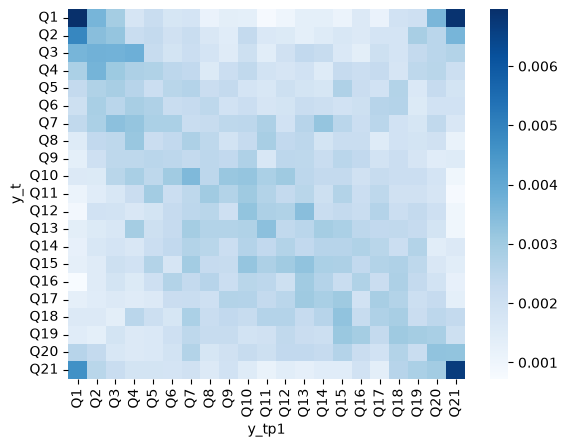

In [30]:
sns.heatmap(quantile_joint, cmap='Blues')

<Axes: xlabel='y_tp1', ylabel='y_t'>

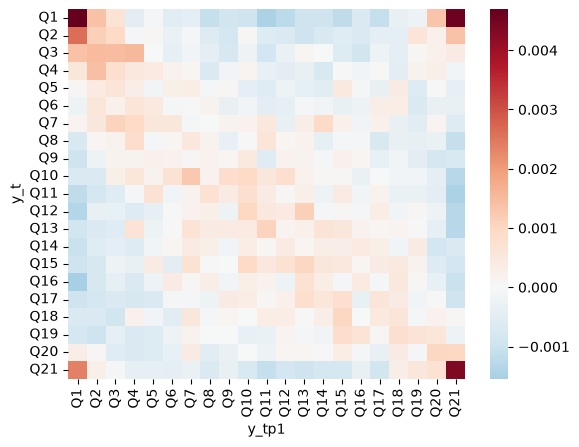

In [31]:
sns.heatmap(quantile_joint - 1/bins**2, cmap='RdBu_r', center=0)

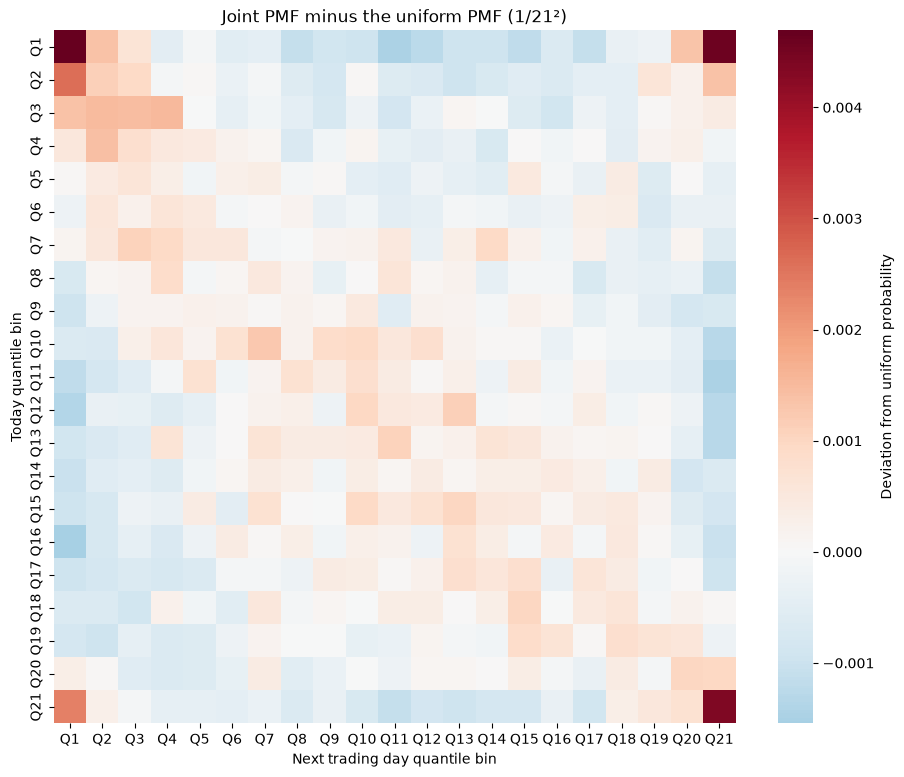

In [33]:
# Compare the joint PMF with a uniform joint distribution over 21 x 21 cells
uniform_joint_probability = 1 / bins**2
joint_deviation_from_uniform = (
    joint_pmf_21.drop(index='All', columns='All') - uniform_joint_probability
)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    joint_deviation_from_uniform, cmap='RdBu_r', center=0,
    ax=ax, cbar_kws={'label': 'Deviation from uniform probability'}
)
ax.set(
    xlabel='Next trading day quantile bin',
    ylabel='Today quantile bin',
    title='Joint PMF minus the uniform PMF (1/21²)'
)
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

#### I see that the strongestr deviations are around the more extreme quantile bins concentrated in the corners.

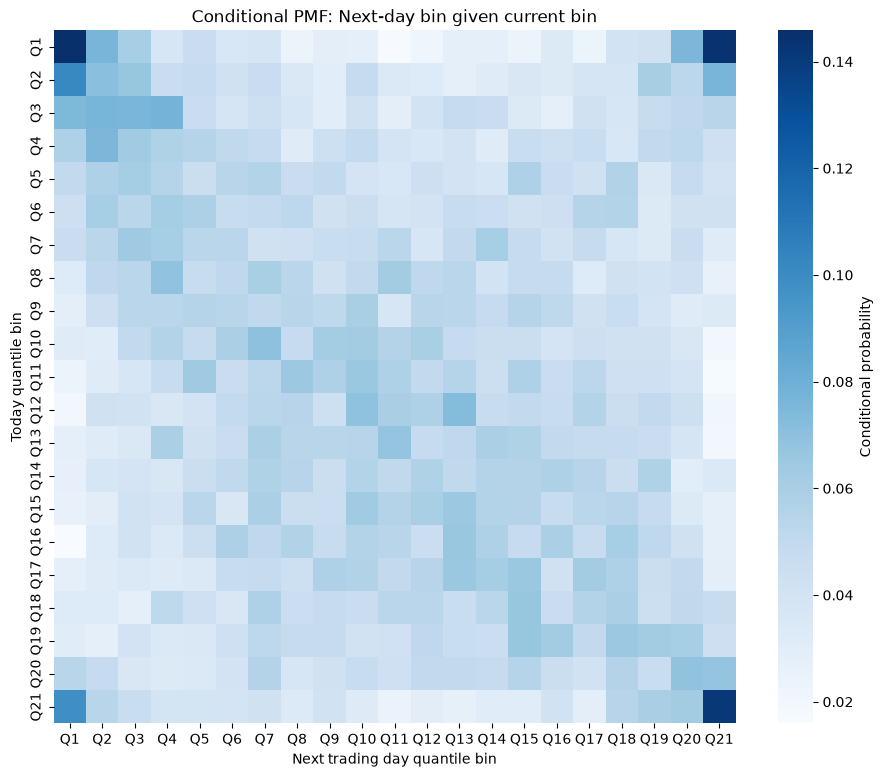

In [35]:
# Conditional PMF: probability of tomorrow's quantile bin given today's bin
conditional_pmf_21 = pd.crosstab(
    df['y_t'], df['y_tp1'], normalize='index'
)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    conditional_pmf_21, cmap='Blues', ax=ax,
    cbar_kws={'label': 'Conditional probability'}
)
ax.set(
    xlabel='Next trading day quantile bin',
    ylabel='Today quantile bin',
    title='Conditional PMF: Next-day bin given current bin'
)
plt.show()

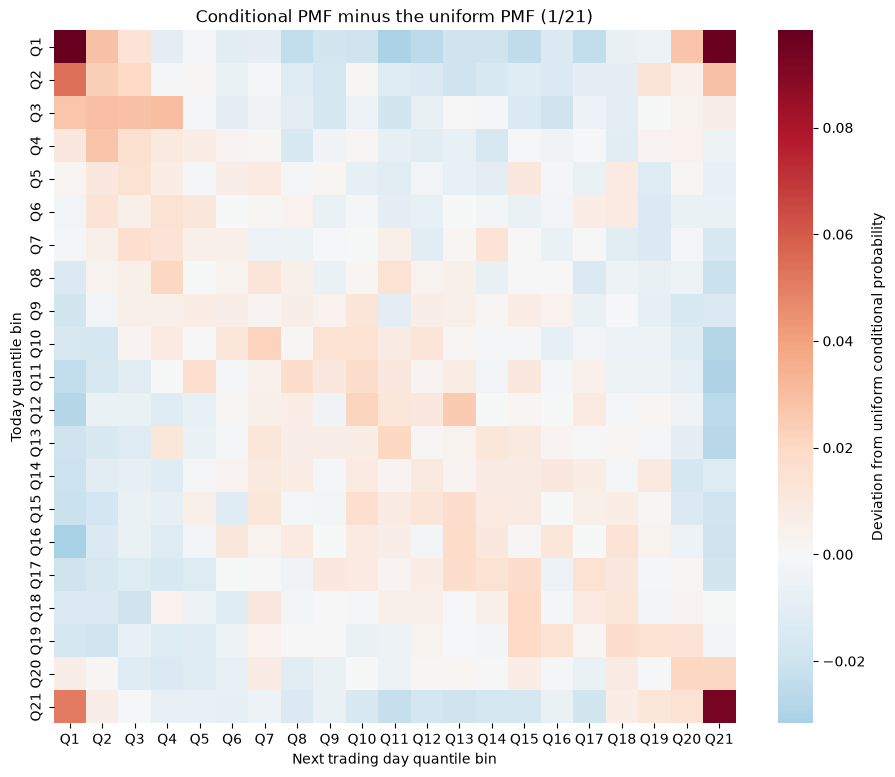

In [36]:
# Compare each conditional distribution with a uniform distribution over 21 bins
uniform_conditional_probability = 1 / bins
conditional_deviation_from_uniform = (
    conditional_pmf_21 - uniform_conditional_probability
)

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(
    conditional_deviation_from_uniform, cmap='RdBu_r', center=0, ax=ax,
    cbar_kws={'label': 'Deviation from uniform conditional probability'}
)
ax.set(
    xlabel='Next trading day quantile bin',
    ylabel='Today quantile bin',
    title='Conditional PMF minus the uniform PMF (1/21)'
)
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

#### The next day retunrs in the middle quantile bins are generally more likely than a probability of 1/21 while the mives into the most extremem binas are less commont that most of the current states. The strongest deviations are after the most extreme retunrs like in q1 adn q21.

In [37]:
# Tomorrow's return summary, conditional on today's quantile bin
df['market_return_pct_tp1'] = df['market_return_pct'].shift(-1)
next_return_summary_21 = (
    df.groupby('y_t', observed=True)['market_return_pct_tp1']
    .agg(['min', 'mean', 'max'])
)
next_return_summary_21

,min,mean,max
y_t,,,
Q1,-17.41,-0.013713,11.22
Q2,-7.36,-0.076712,6.36
Q3,-8.79,-0.097084,11.36
Q4,-8.28,-0.058594,6.16
Q5,-6.89,-0.024211,4.56
Q6,-11.23,-0.022692,6.37
Q7,-3.94,-0.030241,7.37
Q8,-3.40,-0.014303,4.76
Q9,-6.00,0.025860,5.49


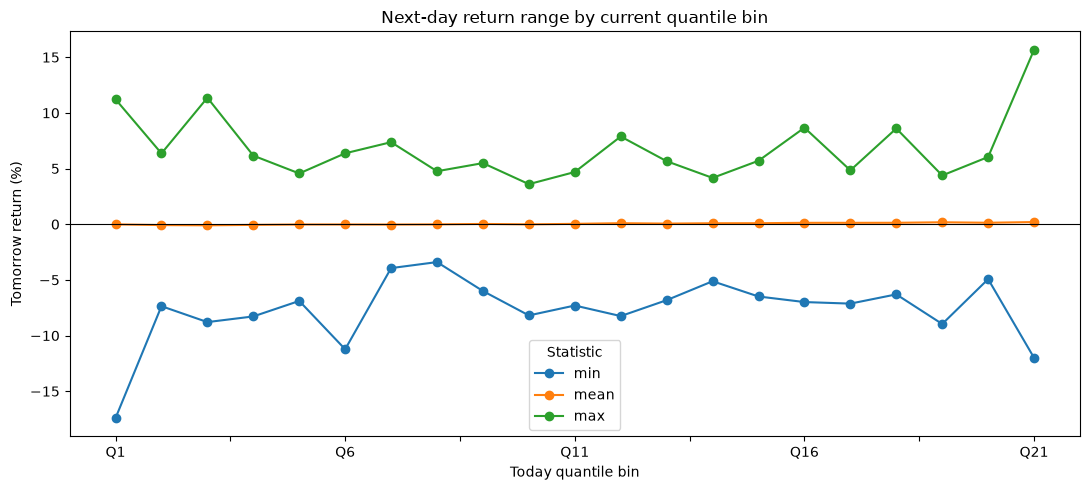

In [38]:
fig, ax = plt.subplots(figsize=(11, 5))
next_return_summary_21.plot(
    y=['min', 'mean', 'max'], marker='o', linewidth=1.5, ax=ax
)
ax.axhline(0, color='black', linewidth=0.8)
ax.set(
    xlabel='Today quantile bin',
    ylabel='Tomorrow return (%)',
    title='Next-day return range by current quantile bin'
)
ax.legend(title='Statistic')
fig.tight_layout()
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

#### The mean next day return is near zero across most of the bins. The current bin provides only weak predictability directionally. The minimum and maximum lines are farther apart after the most extreme bins as well. 

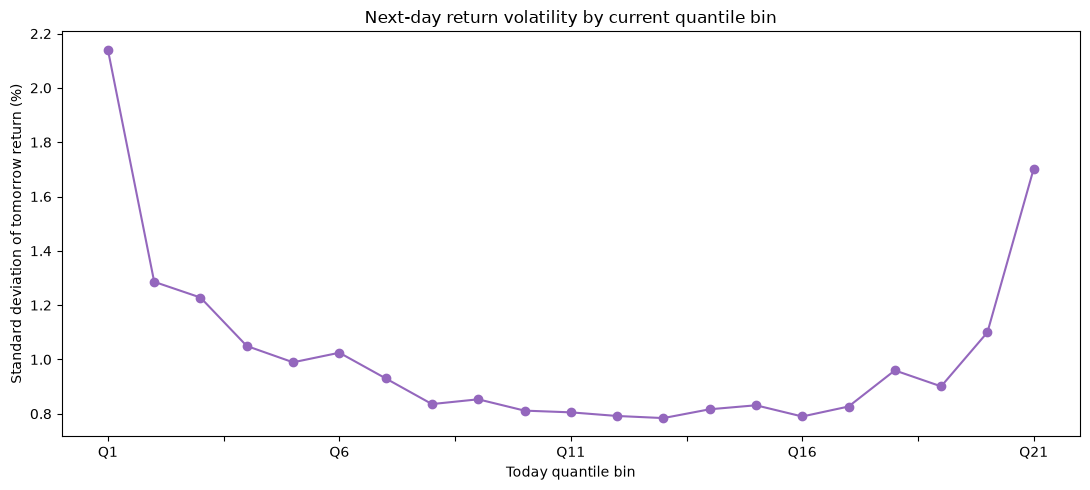

In [39]:
# Standard deviation of tomorrow's return, conditional on the current bin
next_return_std_21 = (
    df.groupby('y_t', observed=True)['market_return_pct_tp1'].std()
)

fig, ax = plt.subplots(figsize=(11, 5))
next_return_std_21.plot(marker='o', linewidth=1.5, color='tab:purple', ax=ax)
ax.set(
    xlabel='Today quantile bin',
    ylabel='Standard deviation of tomorrow return (%)',
    title='Next-day return volatility by current quantile bin'
)
fig.tight_layout()
plt.show()

<div class='alert alert-info'><b>Answer the following:</b>

Do you see any obvious patterns?

</div>

#### The standard deviation is the higehest awter the most extreme current bins, and is lowest after middle range return bins. 

<div class='alert alert-info'><b>Answer the following:</b>

How easy is it to predict the market?
</div>

#### It seems really hard to predict the market because the average next day return stays close to zero, but a large gain or or loss today could suggest that tomorrow has a big change of another large move in either direction. Also, high variability is inserted because world events of the day which could range from things like wars, deaths, foreign affairs, etc., are all capable of significantly shifting the next day turnout. 